# D31. FastAPI 음성 API 서버: STT · TTS REST와 WebSocket, 비동기 처리, 파일 업로드

**음성 AI 전문가 과정 (160h) | 7주차 M7 서비스 배포 & 운영 · Edge AI | 4시간**

## 학습 목표
1. **FastAPI**로 API 서버를 만들고 Colab 안에서 띄워, `httpx` 클라이언트와 자동 문서(Swagger `/docs`)로 호출한다.
2. **STT REST 엔드포인트**: 음성 파일을 **업로드(`UploadFile`)** 받아 받아쓰기 결과를 JSON으로 돌려주고, 잘못된 파일은 **상태 코드(415 · 413)** 로 거절한다.
3. **TTS REST 엔드포인트**: 글자(JSON, `pydantic` 검사)를 받아 **WAV 소리(`audio/wav`)** 로 돌려준다.
4. **비동기 처리**: `async def` 안의 무거운 모델 호출이 서버 전체를 멈추게 하는 것을 재고, `asyncio.to_thread` · `Semaphore` · 백그라운드 작업(`BackgroundTasks`)으로 고친다.
5. **WebSocket 엔드포인트**: 20 ms 소리 조각을 실시간으로 받아 말 끝을 찾고 받아쓰기를 돌려주며, 마지막에 **음성 → 글자 → 답 → 음성**을 한 연결로 처리한다.

## 오늘의 실습 흐름
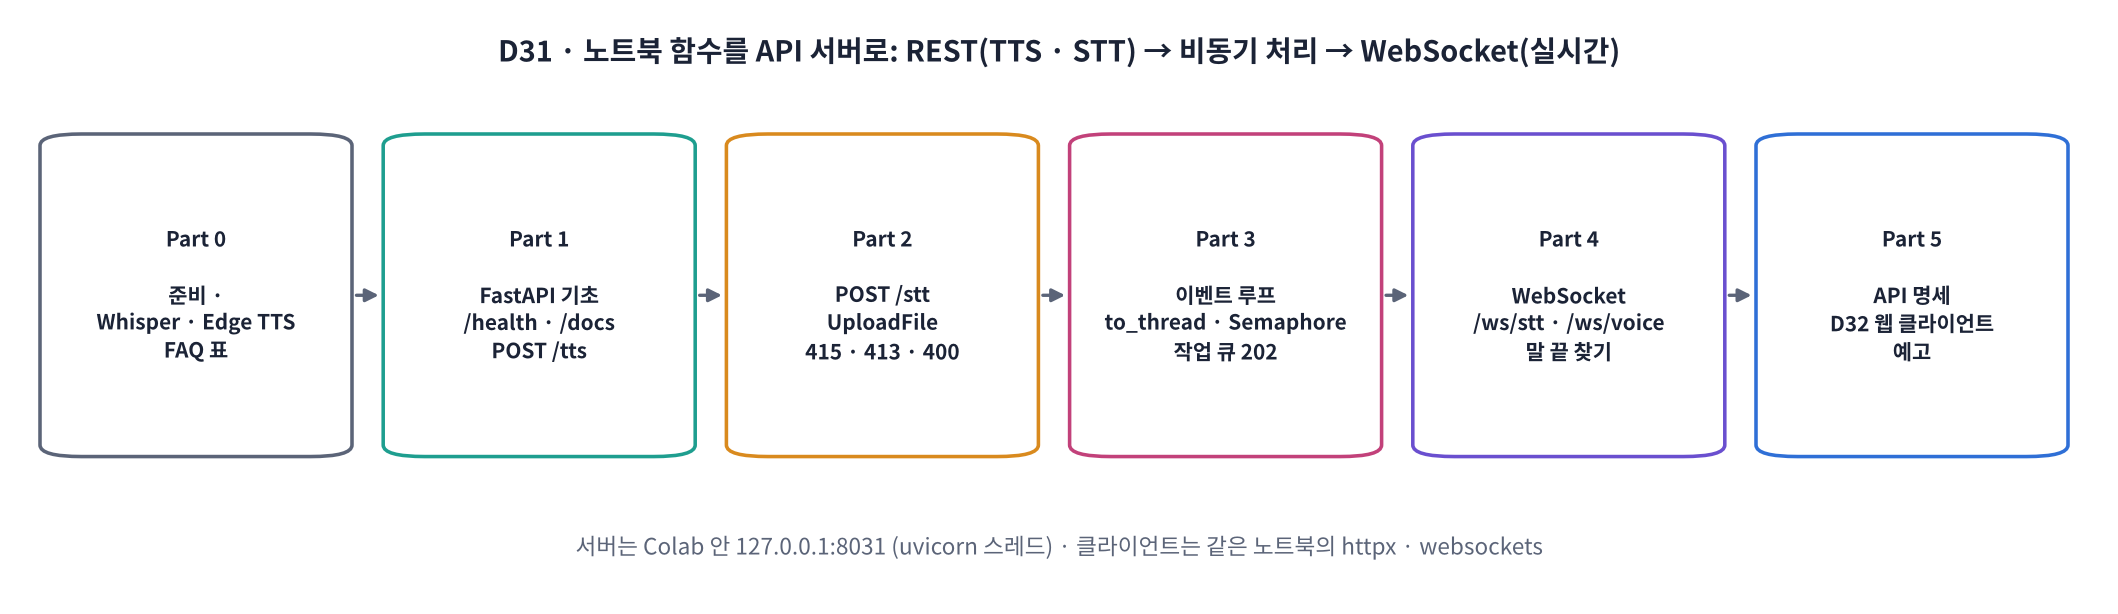

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | API · HTTP · FastAPI 기초, 서버 띄우기, `/health` · `/docs`, TTS REST | Part 0 ~ 1, 워크시트 1교시 | `/health` · `/tts` 호출 결과, Swagger 화면 |
| 2교시 | STT REST: 파일 업로드 · 형식 변환 · 상태 코드(415 · 413 · 422) | Part 2, 워크시트 2교시 | 형식별 업로드 결과표 · 오류 응답표 |
| 3교시 | 비동기 처리: 이벤트 루프 막힘 측정, `to_thread` · `Semaphore` · 작업 큐 | Part 3, 워크시트 3교시 | `/health` 지연 그래프(막힘 vs 해결) · 대기/처리 시간표 |
| 4교시 | WebSocket: 스트리밍 STT · 음성 안내 왕복, API 명세 정리 | Part 4 ~ 5, 워크시트 4교시 | 실시간 받아쓰기 사건 표 · 왕복 통화 타임라인 · API 명세표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day31/animation.html) | 요청 · 응답(D31-2) · 업로드(D31-3) · 상태 코드(D31-4) · 이벤트 루프(D31-5 · 6) · WebSocket(D31-7 · 8) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day31/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. 서버는 **이 Colab 안(127.0.0.1:8031)** 에서 돌고, 같은 노트북의 클라이언트 코드가 요청을 보냅니다.
- 🧩 **빈칸 실습** 셀은 `____`를 채우고 실행하면 ✅ 또는 ❌가 나옵니다. 🔑 **정답 및 해설 보기**를 누르면 정답이 펼쳐집니다.
- ✏️ 표시 셀은 값을 **직접 바꿔** 다시 실행해 보는 셀입니다.
- 🔁 엔드포인트 셀을 **다시 실행해도 됩니다**: 같은 주소의 옛 엔드포인트를 지우고 새로 등록합니다(`drop_routes`).

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** (CPU도 가능, 받아쓰기가 느려짐). 오늘은 **LLM 키가 필요 없습니다**: 답은 한빛치과 FAQ 표에서 찾습니다(✏️ D22의 LLM으로 바꿔 끼울 자리는 표시해 둠).
>
> 🔒 오늘 서버는 이 Colab 안에서만 열립니다. 서버를 인터넷에 공개할 때(D33)는 **인증 · 크기 제한 · 요청 수 제한**이 꼭 필요합니다.

> 🎬 **애니메이션 D31-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#flow) — Part 1~5 로드맵과 시간 계획

## Part 0. 준비 (Whisper · Edge TTS는 D27 ~ D30과 같음)

> 🛠️ `fastapi`(API 만들기) · `uvicorn`(서버 실행기) · `python-multipart`(파일 업로드 해석) · `websockets`(WS 클라이언트) · `httpx`(HTTP 클라이언트)를 설치합니다. Colab에 이미 있는 것은 버전만 맞춥니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt fastapi uvicorn python-multipart websockets httpx soundfile
!pip install -q -c colab_constraints.txt uroman edge-tts
print("✅ 설치 완료")

In [ ]:
import os, re, sys, json, time, random, socket, asyncio, warnings, logging
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
import io, threading, subprocess, base64
import soundfile as sf
import httpx, uvicorn, websockets                       # httpx: 클라이언트(요청 보내기) · uvicorn: 서버 실행기 · websockets: WS 클라이언트
from fastapi import FastAPI, UploadFile, File, HTTPException, WebSocket, WebSocketDisconnect, BackgroundTasks
from fastapi.responses import Response, HTMLResponse
from pydantic import BaseModel, Field

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["fastapi", "uvicorn", "pydantic", "torch", "transformers"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

# D16 정규화 (숫자 → 읽는 말): TTS 바로 앞에서 씀
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d+)\s*%", lambda m: sino(int(m.group(1))) + " 퍼센트", t)
    t = re.sub(r"\d+", lambda m: sino(int(m.group(0))), t)
    return re.sub(r"\s+", " ", t).strip()
print(normalize_ko("오후 2시에 3명, 주차는 2시간 무료, 할인 10%"))

In [ ]:
# 🔊 모델 준비 (D27 ~ D30과 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS) + 오늘의 사용자 말 세 마디
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

SAY1 = "안녕하세요, 진료 시간이 어떻게 되나요?"            # 오늘의 사용자 말 세 마디 (한빛치과 안내 전화)
SAY2 = "주차는 가능한가요?"
SAY3 = "스케일링 비용은 얼마예요?"
VOICE1, VOICE2, VOICE3 = make_voice(SAY1), make_voice(SAY2), make_voice(SAY3)
for i, v in enumerate([VOICE1, VOICE2, VOICE3], 1): play(v, SR, f"사용자 말 {i}")
print("받아쓰기 확인:", stt(VOICE1), "/", stt(VOICE2))

In [ ]:
# 📋 한빛치과 FAQ: 오늘 서버의 '머리' (✏️ D22의 LLM 호출로 바꿔 끼울 수 있는 자리)
FAQ = [
    (["진료 시간", "몇 시", "영업", "언제 문"], "평일은 오전 아홉 시 반부터 오후 여섯 시 반까지, 토요일은 오후 한 시까지 진료합니다."),
    (["주차"], "건물 지하 주차장을 이용하시면 진료 당일 두 시간 무료입니다."),
    (["스케일링", "비용", "얼마", "가격"], "스케일링은 보험 적용 시 약 1만 5천 원입니다."),
    (["예약"], "예약은 전화나 한빛치과 앱에서 하실 수 있어요. 원하시는 날짜와 시간을 말씀해 주세요."),
]
def answer(text):                                        # 글자 → 답 (키워드가 가장 많이 맞는 항목)
    best = max(FAQ, key=lambda kv: sum(k in text for k in kv[0]))
    return best[1] if any(k in text for k in best[0]) else "죄송해요, 다시 한 번 말씀해 주시겠어요? 진료 시간, 주차, 비용, 예약을 안내해 드릴 수 있어요."
for q in [SAY1, SAY2, SAY3, "안녕하세요"]:
    print(f"{q} → {answer(q)}")

## Part 1. API 서버의 기초: 요청 · 응답 · FastAPI  ·  1교시

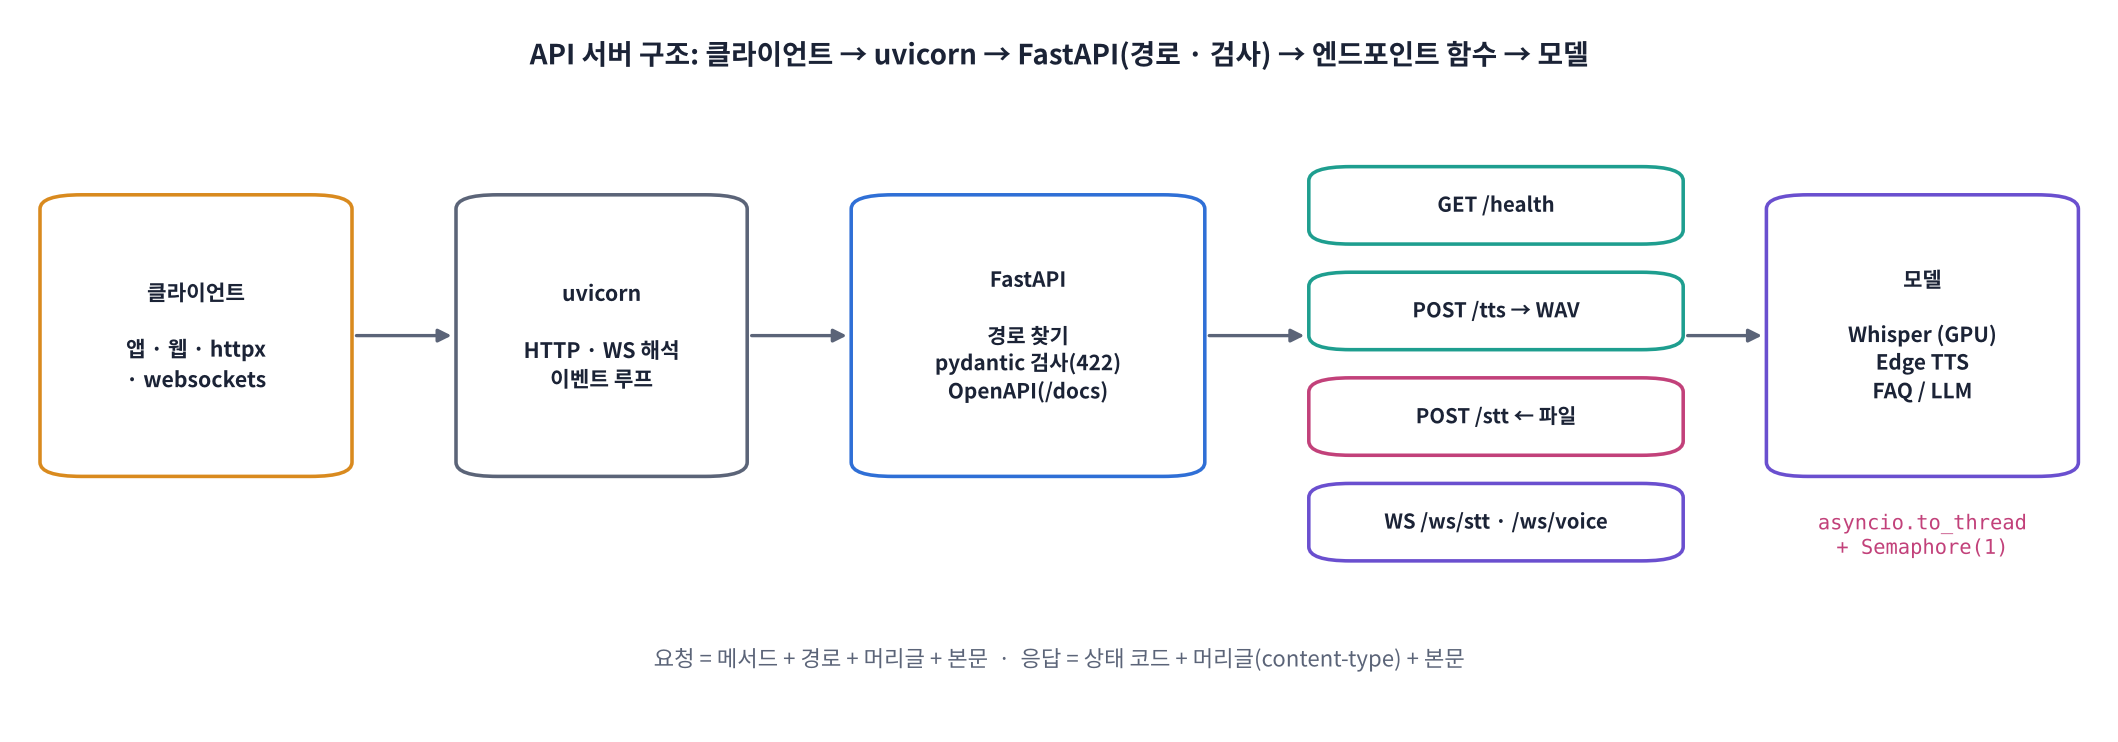

지금까지는 Whisper · TTS를 **노트북 안에서 함수로** 불렀습니다. 앱 · 웹 · 다른 서비스가 이 기능을 쓰게 하려면 **API 서버**로 감싸 **네트워크 너머에서** 부를 수 있게 해야 합니다.

| 이름 | 뜻 | 오늘의 예 |
|---|---|---|
| **HTTP 요청** | 메서드 + 주소(경로) + 머리글(header) + 본문(body) | `POST /tts`, 본문 `{"text": "안녕하세요"}` |
| **HTTP 응답** | 상태 코드 + 머리글 + 본문 | `200`, `content-type: audio/wav`, WAV 바이트 |
| **REST** | 주소 = 자원, 메서드 = 할 일 (`GET` 읽기, `POST` 만들기 · 처리) | `GET /health`, `POST /stt` |
| **엔드포인트** | 주소 하나 + 그 주소를 처리하는 함수 | `@app.post("/stt")` 아래 함수 |
| **WebSocket** | 연결을 열어 두고 **양쪽이 언제든** 메시지를 보냄 (Part 4) | `/ws/stt`, 20 ms 소리 조각 |

> 🍎 **비유**: REST는 **창구에 서류 한 장 내고 결과를 받아 가는 민원실**, WebSocket은 **전화를 걸어 놓고 계속 주고받는 상담**입니다.
>
> 💬 **쉽게 말하면**: FastAPI는 **"이 주소로 이런 요청이 오면 이 파이썬 함수를 불러라"** 를 장식자 한 줄로 적게 해 주는 도구입니다.

> 🎬 **애니메이션 D31-2:** [요청과 응답의 일생](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#http) — 클라이언트 → uvicorn → FastAPI 경로 찾기 → 검사 → 함수 → 응답

In [ ]:
# 🚀 서버 틀 만들기 + Colab 안에서 띄우기 (빈칸 실습 1)
app = FastAPI(title="한빛치과 음성 API", version="0.31", description="D31 실습: STT · TTS · WebSocket")
PORT = 8031
BASE = f"http://127.0.0.1:{PORT}"

def drop_routes(*paths):                                 # 같은 주소의 옛 엔드포인트 지우기 (셀을 다시 실행해도 안전하게)
    app.router.routes = [r for r in app.router.routes if getattr(r, "path", None) not in paths]
    app.openapi_schema = None                            # /docs 문서도 새로 만들게

drop_routes("/health")
@app.____("/health", summary="서버 상태")                # 빈칸 1: '읽기' 요청(GET)을 받는 장식자
async def health():
    return {"ok": True, "gpu": GPU, "asr": ASR_NAME, "tts": TTS_ENGINE, "time": time.strftime("%H:%M:%S")}

def start_server():                                      # uvicorn을 별도 스레드에서 실행 (노트북은 계속 쓸 수 있게)
    global server, server_thread
    if "server" in globals() and server.started and not server.should_exit:
        return "이미 실행 중"
    server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=PORT, log_level="warning"))
    server_thread = threading.Thread(target=server.run, daemon=True)
    server_thread.start()
    for _ in range(100):
        if server.started: return "시작함"
        time.sleep(0.05)
    return "시작 실패"

print("서버:", start_server(), "→", BASE)
client = httpx.AsyncClient(base_url=BASE, timeout=60)    # 클라이언트: 같은 노트북에서 요청을 보내는 쪽
r = await client.get("/health")
print("GET /health →", r.status_code, r.json())
check(r.status_code == 200 and r.json()["ok"], "GET 요청을 처리하는 FastAPI 장식자 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
@app.get("/health")
async def health(): ...
```

**해설**: `@app.get(경로)`는 '이 경로로 오는 **GET** 요청은 아래 함수가 처리한다'는 등록입니다. 함수가 돌려준 dict는 FastAPI가 **JSON**으로 바꿔 응답합니다. `/health`처럼 서버가 살아 있는지만 알려 주는 엔드포인트는 배포(D33)에서 **헬스 체크**로 씁니다. `POST`는 `@app.post`, WebSocket은 `@app.websocket`입니다.

</details>

In [ ]:
# 📖 자동 문서(Swagger UI): 브라우저에서 엔드포인트를 눌러 직접 시험해 볼 수 있음
try:
    from google.colab.output import eval_js
    DOCS_URL = eval_js(f"google.colab.kernel.proxyPort({PORT})") + "docs"   # Colab이 이 포트를 내 브라우저에만 열어 줌
    display(Markdown(f"👉 [Swagger 문서 열기]({DOCS_URL}) (새 탭, 이 Colab을 연 계정에서만 열림)"))
except Exception:
    print("Colab이 아니라 링크를 만들 수 없습니다. 아래처럼 문서 내용을 직접 확인합니다.")
spec = (await client.get("/openapi.json")).json()          # /docs가 읽는 명세서 (OpenAPI)
print("API 이름:", spec["info"]["title"], "· 버전:", spec["info"]["version"])
print("등록된 경로:", list(spec["paths"]))

### 1-2. TTS REST: 글자 JSON → WAV 소리

👣 **한 단계씩**
1. 요청 본문(JSON)을 **pydantic 모델(`BaseModel`)** 로 받습니다. FastAPI가 형식을 검사해, 틀리면 함수가 불리기 전에 **422**로 거절합니다.
2. 글자를 숫자 읽기로 바꾸고(D16 `normalize_ko`) TTS로 소리를 만듭니다.
3. 소리를 **WAV 바이트**로 바꿔 `Response(content=..., media_type="audio/wav")`로 돌려줍니다. 받는 쪽은 `content-type`을 보고 소리 파일인 줄 압니다.

📐 **핵심 식 하나**: `WAV 크기(바이트) ≈ 44 + 샘플 수 × 2` (16비트 모노) → 16 kHz 1초 ≈ 32 KB

In [ ]:
# 🧩 빈칸 실습 2 · 3: TTS 엔드포인트 (POST /tts)
class TTSRequest(____):                                  # 빈칸 2: pydantic의 '요청 모양' 부모 클래스
    text: str = Field(..., min_length=1, max_length=300, description="읽을 글자 (300자 이하)")
    voice: str = Field(VOICE_BOT, description="Edge 신경망 음성 이름")

def wav_bytes(y, sr=SR):                                 # numpy 소리 → WAV 파일 바이트 (16비트)
    buf = io.BytesIO(); sf.write(buf, np.clip(y, -1, 1), sr, format="WAV", subtype="PCM_16")
    return buf.getvalue()

drop_routes("/tts")
@app.post("/tts", summary="글자 → 소리 (WAV)")
async def tts_endpoint(req: TTSRequest):
    t0 = time.perf_counter()
    y = await asyncio.to_thread(tts, normalize_ko(req.text), 0, req.voice)    # 무거운 일은 스레드로 (Part 3에서 자세히)
    return Response(content=wav_bytes(y), media_type=____,                    # 빈칸 3: WAV 소리의 미디어 타입
                    headers={"X-Synth-Seconds": f"{time.perf_counter() - t0:.3f}", "X-Audio-Seconds": f"{len(y) / SR:.2f}"})

r = await client.post("/tts", json={"text": "평일은 오전 9시 반부터 진료합니다."})
print("POST /tts →", r.status_code, r.headers["content-type"], f"{len(r.content):,} 바이트",
      "· 합성", r.headers["x-synth-seconds"], "초 · 소리", r.headers["x-audio-seconds"], "초")
y_back, sr_back = sf.read(io.BytesIO(r.content), dtype="float32")
play(y_back, sr_back, "API가 돌려준 WAV")
bad = await client.post("/tts", json={"text": ""})          # 형식이 틀린 요청 → 함수가 불리기도 전에 422
print("빈 글자 요청 →", bad.status_code, bad.json()["detail"][0]["msg"])
check(r.status_code == 200 and r.headers["content-type"] == "audio/wav" and bad.status_code == 422,
      "pydantic 요청 모델의 부모 클래스와 WAV의 미디어 타입 글자를 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
class TTSRequest(BaseModel): ...
return Response(content=wav_bytes(y), media_type="audio/wav", ...)
```

**해설**: `BaseModel`을 물려받은 클래스를 함수 인자로 쓰면 FastAPI가 요청 본문 JSON을 그 모양으로 **검사 · 변환**하고, `Field(min_length=1, max_length=300)` 같은 규칙을 어기면 **422 Unprocessable Entity**와 이유를 돌려줍니다. 응답의 `media_type="audio/wav"`는 `content-type` 머리글이 되어, 브라우저 · 앱이 이것을 소리로 재생합니다(MP3면 `audio/mpeg`).

</details>

**❓ 생각해 보기**: TTS 결과를 **JSON 안에 base64 글자**로 넣어 보내는 방법(`{"audio": "UklGR..."}`)도 있습니다. 오늘처럼 **WAV 바이트를 그대로** 보내는 것과 비교하면?

<details>
<summary>답 보기</summary>

base64는 바이트를 글자로 바꾸느라 크기가 약 **4/3배(33%)** 커지고, 양쪽에서 바꾸는 시간이 듭니다. 대신 소리와 함께 다른 정보(받아쓰기 · 시간 정보 등)를 한 JSON에 담기 편합니다. 소리만 보낼 때는 오늘처럼 **바이트 + 머리글(X-…)** 이 효율적이고, 브라우저 `<audio src=…>`로 바로 재생할 수도 있습니다.

</details>

> 📝 **워크시트 1교시** 10문항을 풀어 보세요.

## Part 2. STT REST: 음성 파일 업로드 → 받아쓰기 JSON  ·  2교시

👣 **한 단계씩 (`POST /stt`)**
1. 클라이언트가 파일을 **multipart/form-data**로 보냅니다(웹 폼의 '파일 첨부'와 같은 방식). FastAPI는 `UploadFile`로 받습니다: 파일 이름 · `content_type` · 내용(`await file.read()`).
2. **문지기 검사**: 받을 수 있는 형식인가(아니면 **415**) · 너무 크지 않은가(아니면 **413**) · 풀 수 있는 소리인가(아니면 **400**).
3. 어떤 형식이든 **16 kHz 모노 float32**로 풀어(WAV · FLAC은 soundfile, MP3 · WebM · Ogg는 ffmpeg) Whisper에 넣습니다.
4. 결과를 JSON으로: 글자 · 소리 길이 · 처리 시간 · **RTF**.

📐 **핵심 식 하나**: `RTF(실시간 배율) = 처리 시간 ÷ 소리 길이` → 1보다 작아야 '말하는 속도보다 빨리' 받아쓴다 (D8).

> 🍎 **비유**: 우체국 창구입니다. 받을 수 없는 물건(형식)은 **415**, 너무 큰 소포는 **413**, 포장이 찢어져 내용을 알 수 없으면 **400**, 송장(필수 칸)이 비었으면 **422**. 문지기 검사를 통과한 것만 안쪽(Whisper)으로 보냅니다.

> 🎬 **애니메이션 D31-3:** [업로드 한 건 해부](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#upload) — multipart 요청의 생김새와 UploadFile이 꺼내 주는 것

In [ ]:
# 🧩 빈칸 실습 4 · 5: STT 엔드포인트 (POST /stt, 파일 업로드)
ALLOWED = {"audio/wav", "audio/x-wav", "audio/wave", "audio/flac", "audio/mpeg", "audio/mp3", "audio/ogg", "audio/webm"}
MAX_BYTES = 10 * 1024 * 1024                             # ✏️ 10 MB (16 kHz WAV 약 5분)

def decode_audio(data: bytes) -> np.ndarray:             # 어떤 형식이든 → 16 kHz 모노 float32
    try:
        y, sr = sf.read(io.BytesIO(data), dtype="float32", always_2d=True)          # WAV · FLAC · (OGG)
        y = y.mean(axis=1)
        return librosa.resample(y, orig_sr=sr, target_sr=SR) if sr != SR else y
    except Exception:
        p = subprocess.run(["ffmpeg", "-v", "error", "-i", "pipe:0", "-f", "f32le", "-ac", "1", "-ar", str(SR), "pipe:1"],
                           input=data, capture_output=True)                           # MP3 · WebM(브라우저 녹음) 등
        if p.returncode != 0 or not p.stdout:
            raise ValueError("소리로 풀 수 없는 파일")
        return np.frombuffer(p.stdout, dtype=np.float32).copy()

async def transcribe(y):                                 # 받아쓰기 (지금은 '그냥' 부름 → Part 3에서 고칠 곳)
    t0 = time.perf_counter()
    text = stt(y)
    return text, 0.0, time.perf_counter() - t0           # (글자, 기다린 시간, 처리 시간)

drop_routes("/stt")
@app.post("/stt", summary="소리 파일 → 글자")
async def stt_endpoint(file: ____ = File(..., description="WAV · FLAC · MP3 · OGG · WebM")):   # 빈칸 4: 업로드 파일 타입
    if file.content_type not in ALLOWED:
        raise ____(status_code=415, detail=f"지원하지 않는 형식: {file.content_type}")   # 빈칸 5: 'HTTP 오류 응답' 예외
    data = await file.read()
    if len(data) > MAX_BYTES:
        raise HTTPException(status_code=413, detail=f"파일이 너무 큼: {len(data):,} 바이트 > {MAX_BYTES:,}")
    try:
        y = decode_audio(data)
    except ValueError as e:
        raise HTTPException(status_code=400, detail=str(e))
    text, waited, worked = await transcribe(y)
    return {"text": text, "audio_sec": round(len(y) / SR, 2), "wait_sec": round(waited, 3),
            "stt_sec": round(worked, 3), "rtf": round(worked / max(len(y) / SR, 1e-6), 3), "filename": file.filename}

def encode(y, fmt, sr=SR, channels=1):                   # 시험용 파일 만들기: numpy → wav · mp3 · webm 바이트
    y2 = librosa.resample(y, orig_sr=SR, target_sr=sr) if sr != SR else y
    if channels == 2: y2 = np.stack([y2, y2], axis=1)
    if fmt in ("wav", "flac"):
        buf = io.BytesIO(); sf.write(buf, y2, sr, format=fmt.upper()); return buf.getvalue()
    codec = {"mp3": ["-c:a", "libmp3lame", "-b:a", "64k", "-f", "mp3"], "webm": ["-c:a", "libopus", "-b:a", "32k", "-f", "webm"]}[fmt]
    p = subprocess.run(["ffmpeg", "-v", "error", "-f", "f32le", "-ar", str(sr), "-ac", str(channels), "-i", "pipe:0", *codec, "pipe:1"],
                       input=np.asarray(y2, np.float32).tobytes(), capture_output=True)
    return p.stdout

FILES = [("16 kHz 모노 WAV", "voice1.wav", encode(VOICE1, "wav"), "audio/wav"),
         ("48 kHz 스테레오 WAV", "voice1_48k.wav", encode(VOICE1, "wav", 48000, 2), "audio/wav"),
         ("FLAC", "voice2.flac", encode(VOICE2, "flac"), "audio/flac"),
         ("MP3 64 kbps", "voice3.mp3", encode(VOICE3, "mp3"), "audio/mpeg"),
         ("WebM Opus (브라우저 녹음)", "voice1.webm", encode(VOICE1, "webm", 48000), "audio/webm")]
rows = []
for label, name, data, ctype in FILES:
    r = await client.post("/stt", files={"file": (name, data, ctype)})
    j = r.json()
    rows.append({"파일": label, "크기(KB)": round(len(data) / 1024, 1), "상태": r.status_code, "글자": j.get("text", "")[:30],
                 "소리(초)": j.get("audio_sec"), "STT(초)": j.get("stt_sec"), "RTF": j.get("rtf")})
display(pd.DataFrame(rows))
bad = await client.post("/stt", files={"file": ("memo.txt", b"hello", "text/plain")})
print("텍스트 파일 →", bad.status_code, bad.json()["detail"])
check(all(r["상태"] == 200 for r in rows) and bad.status_code == 415, "업로드 파일 타입(UploadFile)과 HTTP 오류 예외(HTTPException) 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
async def stt_endpoint(file: UploadFile = File(...)):
    if file.content_type not in ALLOWED:
        raise HTTPException(status_code=415, detail=...)
```

**해설**: `UploadFile`은 업로드된 파일을 **메모리 · 임시 파일**로 받아 `filename` · `content_type` · `await read()`를 줍니다(`python-multipart`가 multipart 본문을 해석). `HTTPException`을 `raise`하면 함수가 거기서 멈추고 FastAPI가 `{"detail": ...}` JSON과 그 **상태 코드**로 응답합니다. 4xx는 '보낸 쪽 잘못', 5xx는 '서버 잘못'입니다.

</details>

In [ ]:
# 🚦 문지기 검사 모아 보기: 어떤 요청이 몇 번 상태 코드로 거절되나
cases = [
    ("정상 WAV", {"files": {"file": ("ok.wav", encode(VOICE1, "wav"), "audio/wav")}}),
    ("이미지 파일", {"files": {"file": ("photo.png", b"\x89PNG....", "image/png")}}),
    ("11 MB WAV", {"files": {"file": ("big.wav", b"\0" * (11 * 1024 * 1024), "audio/wav")}}),
    ("깨진 WAV", {"files": {"file": ("broken.wav", b"RIFF1234WAVEjunk", "audio/wav")}}),
    ("파일 칸 이름이 틀림", {"files": {"audio": ("ok.wav", encode(VOICE1, "wav"), "audio/wav")}}),
]
rows = []
for label, kw in cases:
    r = await client.post("/stt", **kw)
    d = r.json().get("detail", r.json().get("text"))
    rows.append({"요청": label, "상태 코드": r.status_code, "응답": (d if isinstance(d, str) else json.dumps(d, ensure_ascii=False))[:70]})
display(pd.DataFrame(rows))

| 상태 코드 | 뜻 | 오늘 언제 |
|---|---|---|
| **200** OK | 성공 | 받아쓰기 · 합성 성공 |
| **202** Accepted | 접수함, 나중에 처리 | Part 3 작업 큐 |
| **400** Bad Request | 요청 내용이 이상함 | 깨진 소리 파일 |
| **413** Content Too Large | 너무 큼 | 10 MB 넘는 파일 |
| **415** Unsupported Media Type | 받을 수 없는 형식 | 이미지 · 텍스트 파일 |
| **422** Unprocessable Content | 형식 검사 실패 (FastAPI 자동) | 빈 글자, 파일 칸 이름 틀림 |
| **429** Too Many Requests | 요청이 너무 많음 | (D33 · D34 요청 수 제한) |
| **500** Internal Server Error | 서버 안 오류 | 처리하지 못한 예외 |

> 🎬 **애니메이션 D31-4:** [상태 코드 고르기](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#status) — 상황을 보고 알맞은 코드를 골라 보기

**❓ 생각해 보기**: 413은 파일을 **다 읽은 뒤** 크기를 재서 거절했습니다(`await file.read()`). 누군가 1 GB 파일을 계속 올리면 어떤 문제가 생기고, 어떻게 막을까요?

<details>
<summary>답 보기</summary>

다 읽는 동안 서버 메모리 · 네트워크를 1 GB씩 쓰게 되어 몇 번만으로도 서버가 버티지 못합니다(서비스 거부 공격). 그래서 실서비스에서는 ① 앞단 프록시(nginx 등)에서 **요청 크기 제한**(`client_max_body_size`), ② `Content-Length` 머리글을 먼저 보고 거절, ③ 조금씩 읽다가 한도를 넘으면 즉시 중단, ④ **인증 · 요청 수 제한(429)** 을 함께 씁니다(D33 · D34).

</details>

> 📝 **워크시트 2교시** 10문항을 풀어 보세요.

## Part 3. 비동기 처리: 무거운 모델이 서버를 멈추지 않게  ·  3교시

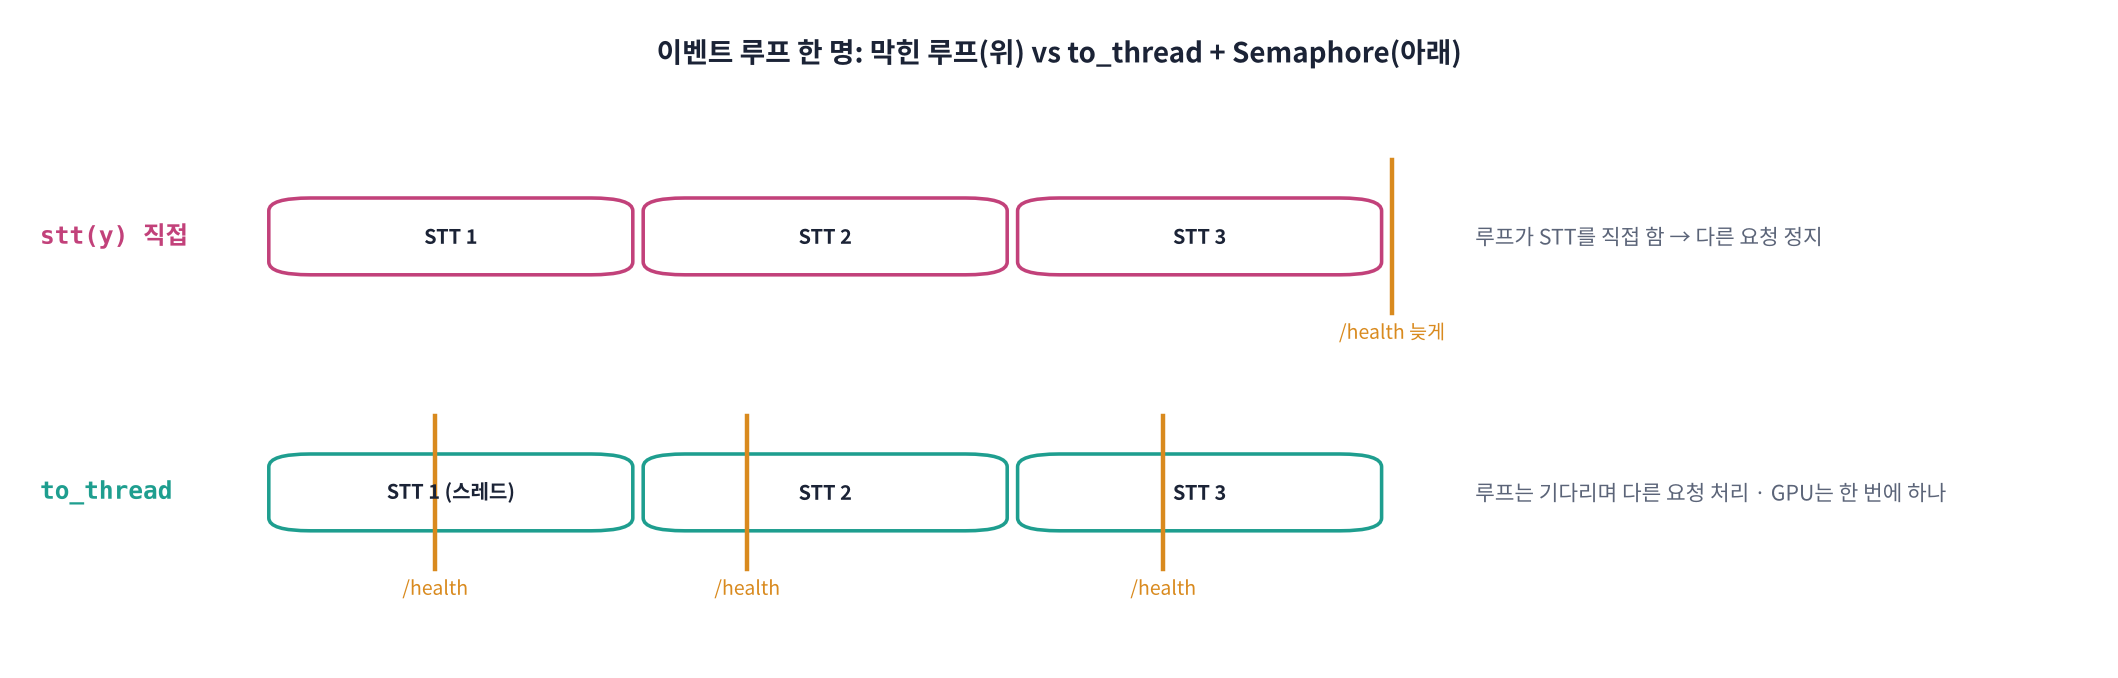

uvicorn · FastAPI는 **이벤트 루프 하나**가 모든 요청을 돌아가며 처리합니다. `await`(기다림)를 만나면 그동안 다른 요청을 처리하죠. 그런데 `async def` 안에서 Whisper처럼 **몇백 ms씩 CPU · GPU를 붙잡는 함수를 그냥 부르면**, 그동안 루프가 멈춰 `/health` 같은 가벼운 요청까지 줄을 서게 됩니다.

| 엔드포인트 모양 | 무거운 함수 호출 | 결과 |
|---|---|---|
| `async def` + 그냥 호출 `stt(y)` | 루프 안에서 실행 | 🚫 **서버 전체 멈춤** (Part 2의 `transcribe`) |
| `def` (async 없이) | FastAPI가 자동으로 스레드 풀에서 실행 | ✅ 멈추지 않음 (스레드 약 40개 한도) |
| `async def` + `await asyncio.to_thread(stt, y)` | 별도 스레드에서 실행, 루프는 기다리는 동안 딴 일 | ✅ 멈추지 않음 + 다른 `await`와 섞어 쓰기 쉬움 |
| 위 + `asyncio.Semaphore(1)` | GPU 모델은 **한 번에 하나씩**, 나머지는 줄 서기 | ✅ 메모리 폭발 · 경쟁 방지, 대기 시간이 보임 |

> 🍎 **비유**: 식당 홀 직원(이벤트 루프)이 한 명입니다. 직원이 주방에 들어가 직접 요리(무거운 계산)를 하면 그동안 손님 주문도 계산도 못 받습니다. **요리는 주방(스레드)에 맡기고**(`to_thread`), 화구가 하나뿐이면 **주문표를 줄 세웁니다**(`Semaphore`).

> 🎬 **애니메이션 D31-5:** [이벤트 루프 한 명](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#loop) — 막힌 루프 vs to_thread: /health 요청이 언제 처리되나

> 🎬 **애니메이션 D31-6:** [번호표 줄 세우기](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#queue) — Semaphore 수를 바꾸면 줄 선 시간 · GPU 메모리가 어떻게 바뀌나

### 3-1. 막힘 재기: 받아쓰기 3건 + `/health`를 50 ms마다

In [ ]:
# 📏 실험 도구: STT 3건을 동시에 보내면서 /health를 50 ms마다 찔러 응답 시간을 잰다
async def probe_health(stop, out, t0):
    while not stop.is_set():
        s = time.perf_counter()
        await client.get("/health")
        out.append((s - t0, time.perf_counter() - s))
        await asyncio.sleep(0.05)

async def stress(label, voices=(VOICE1, VOICE2, VOICE3)):
    t0 = time.perf_counter(); stop = asyncio.Event(); pings = []
    probe = asyncio.ensure_future(probe_health(stop, pings, t0))
    await asyncio.sleep(0.3)
    async def one(i, v):
        s = time.perf_counter() - t0
        r = (await client.post("/stt", files={"file": (f"v{i}.wav", encode(v, "wav"), "audio/wav")})).json()
        return {"요청": f"STT {i}", "보낸 시각": round(s, 2), "받은 시각": round(time.perf_counter() - t0, 2),
                "줄 선 시간": r["wait_sec"], "처리 시간": r["stt_sec"]}
    rows = await asyncio.gather(*[one(i, v) for i, v in enumerate(voices, 1)])
    await asyncio.sleep(0.3); stop.set(); await probe
    return dict(label=label, rows=pd.DataFrame(rows), pings=pings)

before = await stress("blocking: stt(y) inside async def")
display(before["rows"])
print(f"/health 최대 응답 시간: {max(l for _, l in before['pings']) * 1000:.0f} ms  (평소에는 몇 ms)")

In [ ]:
# 🧩 빈칸 실습 6 · 7: 받아쓰기를 스레드로 보내고, GPU는 한 번에 하나씩
GPU_LOCK = asyncio.____(1)                               # 빈칸 7: 동시에 들어갈 수 있는 수를 세는 '번호표' (1 = 한 번에 하나)

async def transcribe(y):                                 # Part 2의 엔드포인트가 이 함수를 부르므로, 엔드포인트는 그대로 둔 채 교체
    t_q = time.perf_counter()
    async with GPU_LOCK:                                 # 차례가 올 때까지 '기다림'(await) → 그동안 루프는 다른 요청 처리
        t0 = time.perf_counter()
        text = await asyncio.____(stt, y)                # 빈칸 6: 무거운 함수를 별도 스레드에서 실행하고 결과를 기다림
    return text, t0 - t_q, time.perf_counter() - t0

after = await stress("fixed: Semaphore(1) + asyncio.to_thread")
display(after["rows"])
fig, ax = plt.subplots(figsize=(12, 3))
for res, c in [(before, "#C8553D"), (after, "#1E9E8F")]:
    t, l = zip(*res["pings"]); ax.plot(t, np.array(l) * 1000, "o", ms=4, color=c, label=res["label"])   # 점 = 보낸 시각 · 높이 = 응답까지 걸린 시간
ax.set_xlabel("seconds since start"); ax.set_ylabel("/health latency (ms)"); ax.set_yscale("log"); ax.legend(fontsize=8)
ax.set_title("while 3 STT requests run: is the server still responsive?", fontsize=10); plt.tight_layout(); plt.show()
mb, ma = max(l for _, l in before["pings"]), max(l for _, l in after["pings"])
print(f"/health 최대 응답: 막힘 {mb * 1000:.0f} ms → 고친 뒤 {ma * 1000:.0f} ms")
check(isinstance(GPU_LOCK, asyncio.Semaphore) and after["rows"]["줄 선 시간"].sum() > 0 and ma < max(0.25, mb),
      "asyncio의 번호표 클래스(Semaphore)와 '스레드로 보내 기다리기' 함수(to_thread)를 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
GPU_LOCK = asyncio.Semaphore(1)
...
async with GPU_LOCK:
    text = await asyncio.to_thread(stt, y)
```

**해설**: `asyncio.to_thread(함수, 인자)`는 함수를 **별도 스레드**에서 돌리고, 끝날 때까지 `await`로 기다리는 동안 이벤트 루프를 놓아줍니다. 그래서 `/health`가 바로 응답합니다. `Semaphore(1)`은 번호표가 1장인 줄: 받아쓰기는 **한 번에 하나만** GPU에 들어가고, 나머지는 `async with`에서 **기다립니다(줄 선 시간)**. GPU 메모리가 넉넉하고 모델이 동시에 안전하면 2 · 3으로 늘리거나, 여러 요청을 묶어 한 번에 처리(배치, D33)합니다.

</details>

### 3-2. 오래 걸리는 일은 '접수증'부터: 작업 큐 (`202 Accepted` + 나중에 조회)

1시간짜리 회의 녹음(D10)을 올리면 받아쓰기가 몇 분 걸립니다. 그동안 HTTP 연결을 붙잡고 있으면 중간 프록시가 끊어 버리기 쉽습니다(보통 30 ~ 60초). 그래서:

👣 ① `POST /jobs/stt` → 바로 **202 + `job_id`** (접수증) → ② 서버는 `BackgroundTasks`로 응답을 보낸 **뒤에** 받아쓰기 → ③ 클라이언트는 `GET /jobs/{job_id}`로 상태를 **조회(polling)** 하거나, 끝나면 알림(웹훅 · WebSocket)을 받음

> 💬 **쉽게 말하면**: 세탁소 맡기기. 옷을 맡기면 **번호표**를 받고, 나중에 번호로 찾으러 옵니다.

In [ ]:
# 🧾 작업 큐: 접수(202) → 백그라운드 처리 → 상태 조회
JOBS = {}                                                # job_id → {"status", "result", ...} (실서비스는 Redis · DB)

async def run_job(job_id, y):
    JOBS[job_id]["status"] = "running"
    text, waited, worked = await transcribe(y)
    JOBS[job_id].update(status="done", result={"text": text, "audio_sec": round(len(y) / SR, 2), "stt_sec": round(worked, 3)})

drop_routes("/jobs/stt", "/jobs/{job_id}")
@app.post("/jobs/stt", status_code=202, summary="긴 파일 받아쓰기 접수")
async def submit_job(background: BackgroundTasks, file: UploadFile = File(...)):
    y = decode_audio(await file.read())
    job_id = f"job-{len(JOBS) + 1:04d}"
    JOBS[job_id] = {"status": "queued", "filename": file.filename, "submitted": time.strftime("%H:%M:%S")}
    background.add_task(run_job, job_id, y)              # 응답을 보낸 '뒤에' 실행
    return {"job_id": job_id, "status": "queued", "poll": f"/jobs/{job_id}"}

@app.get("/jobs/{job_id}", summary="작업 상태 조회")
async def get_job(job_id: str):
    if job_id not in JOBS: raise HTTPException(status_code=404, detail="없는 작업")
    return {"job_id": job_id, **JOBS[job_id]}

long_audio = np.concatenate([VOICE1, VOICE2, VOICE3] * 3)
t0 = time.perf_counter()
r = await client.post("/jobs/stt", files={"file": ("meeting.wav", encode(long_audio, "wav"), "audio/wav")})
print(f"접수 → {r.status_code} {r.json()}  ({time.perf_counter() - t0:.2f}초 만에 응답)")
while True:
    j = (await client.get(r.json()["poll"])).json()
    print(f"  {time.perf_counter() - t0:5.2f}초  상태 = {j['status']}")
    if j["status"] == "done": break
    await asyncio.sleep(0.5)
print("결과:", {**j["result"], "text": j["result"]["text"][:60] + "…"})
print("없는 작업 조회 →", (await client.get("/jobs/job-9999")).status_code)

**❓ 생각해 보기**: 오늘의 `JOBS`는 파이썬 dict라서 서버를 다시 켜면 사라지고, 서버를 2대로 늘리면 서로 모릅니다. 실서비스에서는 어떻게 바꿀까요?

<details>
<summary>답 보기</summary>

작업 목록 · 결과를 **서버 밖의 공용 저장소**(Redis · DB)에 두고, 받아쓰기는 **별도 작업자(worker) 프로세스**(Celery · RQ · arq 등)가 큐에서 꺼내 처리합니다. 그러면 API 서버는 접수 · 조회만 하고, GPU 작업자는 따로 늘리거나 줄일 수 있습니다. D29의 LiveKit Agent Worker가 '방이 생기면 일감을 받는' 것과 같은 구조입니다(D33에서 컨테이너로 나눔).

</details>

> 📝 **워크시트 3교시** 10문항을 풀어 보세요.

## Part 4. WebSocket: 말하는 동안 받아쓰고, 한 연결로 음성 안내까지  ·  4교시

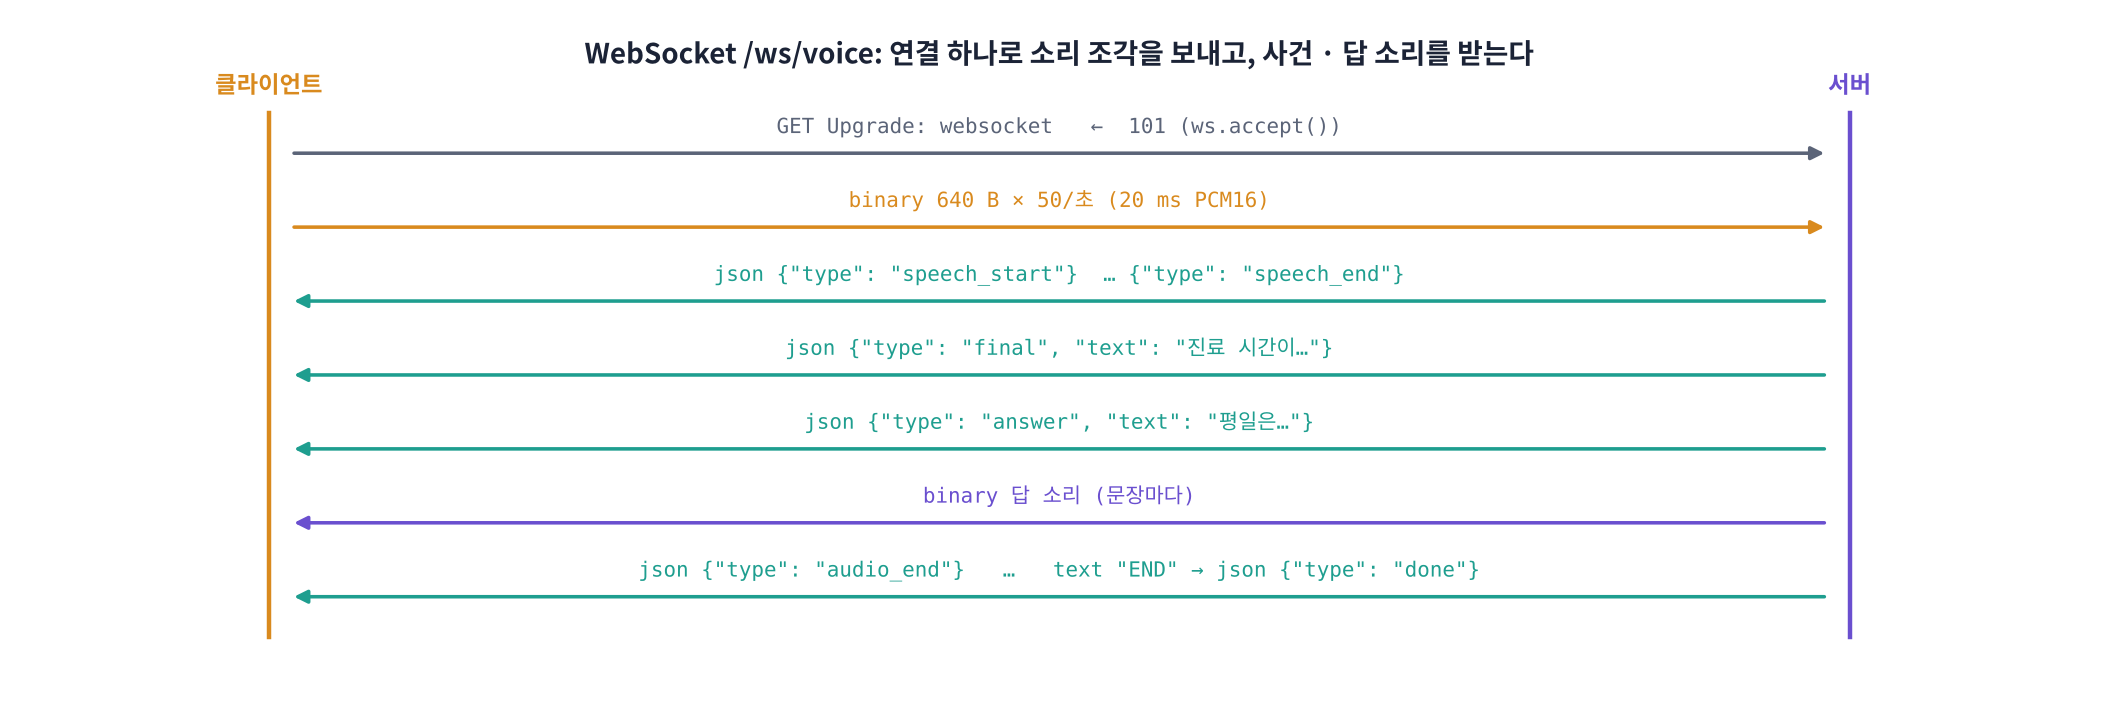

REST `/stt`는 **말이 다 끝난 파일**을 받습니다. 실시간 비서(D27 ~ D30)는 말하는 동안 소리를 조금씩 보내고, 서버가 **말 끝을 찾아** 바로 받아써야 합니다. 이때 연결을 열어 두고 양쪽이 언제든 보내는 **WebSocket**을 씁니다.

**오늘의 메시지 약속 (프로토콜)**

| 방향 | 종류 | 내용 |
|---|---|---|
| 클라이언트 → 서버 | **바이너리** | 20 ms 소리 조각: 16 kHz · 모노 · 16비트 PCM (640 바이트) |
| 클라이언트 → 서버 | 글자 `"END"` | 이제 그만 보냄 |
| 서버 → 클라이언트 | JSON `speech_start` · `speech_end` | 말 시작 · 끝을 찾음 (시각 = 소리 시계) |
| 서버 → 클라이언트 | JSON `final` | 받아쓰기 결과 |
| 서버 → 클라이언트 | JSON `answer` → **바이너리** 소리 → JSON `audio_end` | (4-2) 답 글자, 답 소리, 끝 |

**말 끝 찾기 (에너지 VAD, D4 복습)**: 20 ms마다 소리 크기(dBFS)를 재서 `THRESH_DB`보다 크면 '말', 말이 시작된 뒤 `HANG_SEC` 동안 조용하면 '말 끝'.

📐 **핵심 식 하나**: `dBFS = 20 · log10( RMS )`  (RMS = 소리 조각의 평균 크기, 가장 큰 소리 = 0 dBFS)

> 💬 **쉽게 말하면**: REST는 편지, WebSocket은 전화. 전화를 연 채로 소리를 흘려보내면, 서버는 **문장이 끝날 때마다** 받아쓴 글자를 바로 돌려줍니다.

> 🎬 **애니메이션 D31-7:** [WebSocket 메시지 흐름](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#ws) — 연결 → 바이너리 조각 → 말 시작 · 끝 → final → 답 소리

In [ ]:
# 🧩 빈칸 실습 8 · 9: 실시간 받아쓰기 WebSocket (/ws/stt)
FRAME = SR // 50                                         # 20 ms = 320 샘플 = 640 바이트
THRESH_DB, HANG_SEC, MIN_SPEECH = -38.0, 0.6, 0.25       # ✏️ 말로 볼 크기 · 말 끝 기다림 · 너무 짧은 소리 무시

class Endpointer:                                        # 20 ms 조각을 받아 '말 시작 · 끝'을 찾는 에너지 VAD
    def __init__(self):
        self.t = 0.0; self.in_speech = False; self.quiet = 0.0; self.buf = []; self.start = 0.0
    def feed(self, pcm16: bytes):
        x = np.frombuffer(pcm16, dtype=np.int16).astype(np.float32) / 32768
        db = 20 * np.log10(np.sqrt(np.mean(x ** 2)) + 1e-9)
        events = []
        if not self.in_speech and db > THRESH_DB:
            self.in_speech, self.quiet, self.buf, self.start = True, 0.0, [], self.t
            events.append(("speech_start", self.t, None))
        if self.in_speech:
            self.buf.append(x)
            self.quiet = self.quiet + len(x) / SR if db <= THRESH_DB else 0.0
            if self.quiet >= HANG_SEC:
                self.in_speech = False
                seg = np.concatenate(self.buf)
                if len(seg) / SR - HANG_SEC >= MIN_SPEECH:
                    events.append(("speech_end", self.t + len(x) / SR - HANG_SEC, seg))
        self.t += len(x) / SR
        return events

drop_routes("/ws/stt")
@app.websocket("/ws/stt")
async def ws_stt(ws: WebSocket):
    await ws.____()                                      # 빈칸 8: 연결 요청을 '받아들이기' (이걸 해야 주고받기 시작)
    ep = Endpointer()
    try:
        while True:
            msg = await ws.receive()                     # 바이너리(소리) 또는 글자("END")
            if msg["type"] == "websocket.disconnect": break
            if msg.get("bytes"):
                for kind, t, seg in ep.feed(msg["bytes"]):
                    await ws.____({"type": kind, "t": round(t, 2)})            # 빈칸 9: dict를 JSON 글자로 보내기
                    if kind == "speech_end":
                        text, waited, worked = await transcribe(seg)
                        await ws.send_json({"type": "final", "text": text, "t": round(t, 2), "stt_sec": round(worked, 3)})
            elif msg.get("text") == "END":
                await ws.send_json({"type": "done"}); break
    except WebSocketDisconnect:
        pass

async def stream_and_listen(path, voices, gap=1.5, on_event=None):   # 클라이언트: 소리를 실제 시간 속도로 흘려보내며 메시지를 받음
    audio = np.concatenate([np.concatenate([v, silence(gap)]) for v in voices])
    pcm = (np.clip(audio, -1, 1) * 32767).astype(np.int16).tobytes()
    events = []
    async with websockets.connect(BASE.replace("http", "ws") + path, max_size=None) as ws:
        t0 = time.perf_counter()
        async def receiver():
            async for m in ws:
                ev = json.loads(m) if isinstance(m, str) else {"type": "audio", "bytes": len(m)}
                ev["recv"] = round(time.perf_counter() - t0, 2); events.append(ev)
                if ev["type"] == "done": return
        rx = asyncio.ensure_future(receiver())
        for i in range(0, len(pcm), FRAME * 2):
            await ws.send(pcm[i:i + FRAME * 2])
            await asyncio.sleep(max(0.0, t0 + (i // 2 + FRAME) / SR - time.perf_counter()))   # 실제 시간 속도
        await asyncio.sleep(1.0); await ws.send("END")
        await asyncio.wait_for(rx, 60)
    return events, len(audio) / SR

events, total = await stream_and_listen("/ws/stt", [VOICE1, VOICE2, VOICE3])
df_ws = pd.DataFrame(events)
display(df_ws)
finals = [e for e in events if e["type"] == "final"]
for f in finals:
    print(f"말 끝 {f['t']:5.2f}초 → 글자 도착 {f['recv']:5.2f}초  (지연 {f['recv'] - f['t']:.2f}초 = 말 끝 기다림 {HANG_SEC}초 + STT {f['stt_sec']:.2f}초 + 전송)")
check(len(finals) == 3 and events[-1]["type"] == "done", "WebSocket 연결을 받아들이는 메서드와 dict를 JSON으로 보내는 메서드 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
await ws.accept()
...
await ws.send_json({"type": kind, "t": round(t, 2)})
```

**해설**: WebSocket은 HTTP 요청으로 시작해 **'연결을 바꿔 열자(Upgrade)'** 를 요청합니다. 서버가 `accept()`해야 101 응답과 함께 양방향 연결이 열리고, 그 전에는 주고받을 수 없습니다(인증 실패면 `accept` 대신 `close(code=1008)`). `send_json`은 dict를 JSON **글자 메시지**로, `send_bytes`는 **바이너리 메시지**로 보냅니다. 오늘은 소리 = 바이너리, 사건 = JSON으로 나눴습니다.

</details>

### 4-2. 한 연결로 음성 안내 왕복: 소리 → 받아쓰기 → FAQ 답 → 소리

`/ws/voice`는 `/ws/stt`에 **답하기**를 더합니다. 말 끝이 나오면 받아쓰고(`final`) → FAQ에서 답을 찾고(`answer`) → 답을 **문장마다** TTS로 만들어 바이너리로 흘려보냅니다(`audio` … `audio_end`). D27 ~ D30의 실시간 비서와 같은 일을 **우리 API 서버**가 하는 셈입니다.

> ⚠️ 오늘 서버는 답을 보내는 동안 사용자가 말해도 **끊지 않습니다**(끼어들기 없음). 끼어들기 · 턴 판단 · 지연 측정까지 갖추려면 D27 ~ D30의 Pipecat · LiveKit을 이 서버 뒤에 붙이는 편이 낫습니다. 오늘은 '단순한 API로 어디까지 되나'를 봅니다.

> 🎬 **애니메이션 D31-8:** [말 끝 찾기 손잡이](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#endpoint) — THRESH_DB · HANG_SEC를 바꾸면 말이 어디서 잘리나

In [ ]:
# ☎️ 음성 안내 왕복 WebSocket (/ws/voice) + 클라이언트 (실제 시간, 약 20 ~ 40초)
def sentences(text):                                     # 답을 문장 단위로 (첫 문장부터 빨리 보내려고)
    return [s for s in re.split(r"(?<=[.?!])\s+", text.strip()) if s]

drop_routes("/ws/voice")
@app.websocket("/ws/voice")
async def ws_voice(ws: WebSocket):
    await ws.accept()
    ep = Endpointer()
    try:
        while True:
            msg = await ws.receive()
            if msg["type"] == "websocket.disconnect": break
            if msg.get("bytes"):
                for kind, t, seg in ep.feed(msg["bytes"]):
                    if kind != "speech_end": continue
                    text, _, worked = await transcribe(seg)
                    reply = answer(text)                                    # ✏️ D22의 LLM으로 바꿔 끼울 자리
                    await ws.send_json({"type": "final", "text": text, "t": round(t, 2)})
                    await ws.send_json({"type": "answer", "text": reply})
                    for s in sentences(reply):
                        y = await asyncio.to_thread(tts, normalize_ko(s))
                        await ws.send_bytes((np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes())   # 문장 하나 = 바이너리 하나
                    await ws.send_json({"type": "audio_end"})
            elif msg.get("text") == "END":
                await ws.send_json({"type": "done"}); break
    except WebSocketDisconnect:
        pass

async def voice_call(voices, gap=0.8):                   # 예의 바른 클라이언트: 답 소리를 '다 듣고' gap초 뒤 다음 말
    events, heard, spans = [], [], []
    async with websockets.connect(BASE.replace("http", "ws") + "/ws/voice", max_size=None) as ws:
        t0 = time.perf_counter(); state = {"play_end": 0.0, "turn_done": asyncio.Event()}
        async def receiver():
            async for m in ws:
                now = time.perf_counter() - t0
                if isinstance(m, bytes):                 # 받은 소리: 앞 소리가 끝난 뒤 이어서 '재생'된다고 보고 시각 기록
                    y = np.frombuffer(m, dtype=np.int16).astype(np.float32) / 32768
                    start = max(now, state["play_end"]); heard.append((start, y)); state["play_end"] = start + len(y) / SR
                    events.append({"type": "audio", "recv": round(now, 2), "sec": round(len(y) / SR, 2)})
                    continue
                ev = json.loads(m); ev["recv"] = round(now, 2); events.append(ev)
                if ev["type"] == "audio_end": state["turn_done"].set()
                if ev["type"] == "done": return
        rx = asyncio.ensure_future(receiver())
        k = 0
        async def send_audio(y):
            nonlocal k
            pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes()
            for i in range(0, len(pcm), FRAME * 2):
                await ws.send(pcm[i:i + FRAME * 2]); k += FRAME
                await asyncio.sleep(max(0.0, t0 + k / SR - time.perf_counter()))
        for v in voices:
            spans.append((k / SR, k / SR + len(v) / SR)); await send_audio(v)
            state["turn_done"].clear(); t_turn = time.perf_counter()
            while (not state["turn_done"].is_set() or time.perf_counter() - t0 < state["play_end"] + gap) and time.perf_counter() - t_turn < 40:
                await send_audio(silence(0.02))          # 기다리는 동안에도 조용한 소리를 계속 보냄 (마이크처럼)
        await ws.send("END"); await asyncio.wait_for(rx, 60)
    return dict(events=events, heard=heard, spans=spans)

res_ws = await voice_call([VOICE1, VOICE2, VOICE3])
rows, ev = [], res_ws["events"]
for i, e in enumerate(ev):
    if e["type"] == "final":
        first_audio = next(x for x in ev[i:] if x["type"] == "audio")
        ans = next(x for x in ev[i:] if x["type"] == "answer")
        rows.append({"받아쓰기": e["text"][:24], "답": ans["text"][:30], "말 끝(초)": e["t"],
                     "첫 소리 도착(초)": first_audio["recv"], "말 끝 → 첫 소리(초)": round(first_audio["recv"] - e["t"], 2)})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(12, 2.4))
for a, b in res_ws["spans"]: ax.barh(0, b - a, left=a, color="#D98A1E", height=0.5)
for t, y in res_ws["heard"]: ax.barh(1, len(y) / SR, left=t, color="#1E9E8F", height=0.5)
ax.set_yticks([0, 1]); ax.set_yticklabels(["client mic -> server", "server audio -> client"]); ax.set_xlabel("seconds")
ax.set_title("/ws/voice: speech in, answer audio out over one WebSocket", fontsize=10); plt.tight_layout(); plt.show()
end = max([t + len(y) / SR for t, y in res_ws["heard"]] + [b for _, b in res_ws["spans"]]) + 0.5
mixed = np.zeros(int(end * SR), np.float32)
for (a, _), v in zip(res_ws["spans"], [VOICE1, VOICE2, VOICE3]): i = int(a * SR); mixed[i:i + len(v)] += v[:len(mixed) - i]
for t, y in res_ws["heard"]: i = int(t * SR); mixed[i:i + len(y)] += y[:len(mixed) - i]
play(mixed / (np.abs(mixed).max() + 1e-9) * 0.9, SR, "WebSocket 음성 안내 통화 전체")

**❓ 생각해 보기**: 4-2의 '말 끝 → 첫 소리'를 D28 · D29에서 잰 값과 비교해 보세요. 오늘 서버에서 이 지연을 줄이려면 어디를 바꿀까요?

<details>
<summary>답 보기</summary>

오늘 지연 ≈ `HANG_SEC`(0.6초, 말 끝 기다림) + 받아쓰기 + 첫 문장 TTS. ① `HANG_SEC`를 줄이면 빨라지지만 쉼에서 말이 잘림(D28 저울질), ② 에너지 VAD 대신 Silero VAD · Smart Turn(D28)으로 더 정확히, ③ 첫 문장을 짧게 · TTS 결과 캐시(자주 하는 답은 미리 만든 소리), ④ 스트리밍 STT(D8)로 말하는 동안 미리 받아쓰기. 이런 것을 다 직접 만들기보다 Pipecat · LiveKit(6주차)을 쓰는 이유이기도 합니다.

</details>

> 📝 **워크시트 4교시** 10문항을 풀어 보세요.

## Part 5. 정리: 오늘 만든 API 명세

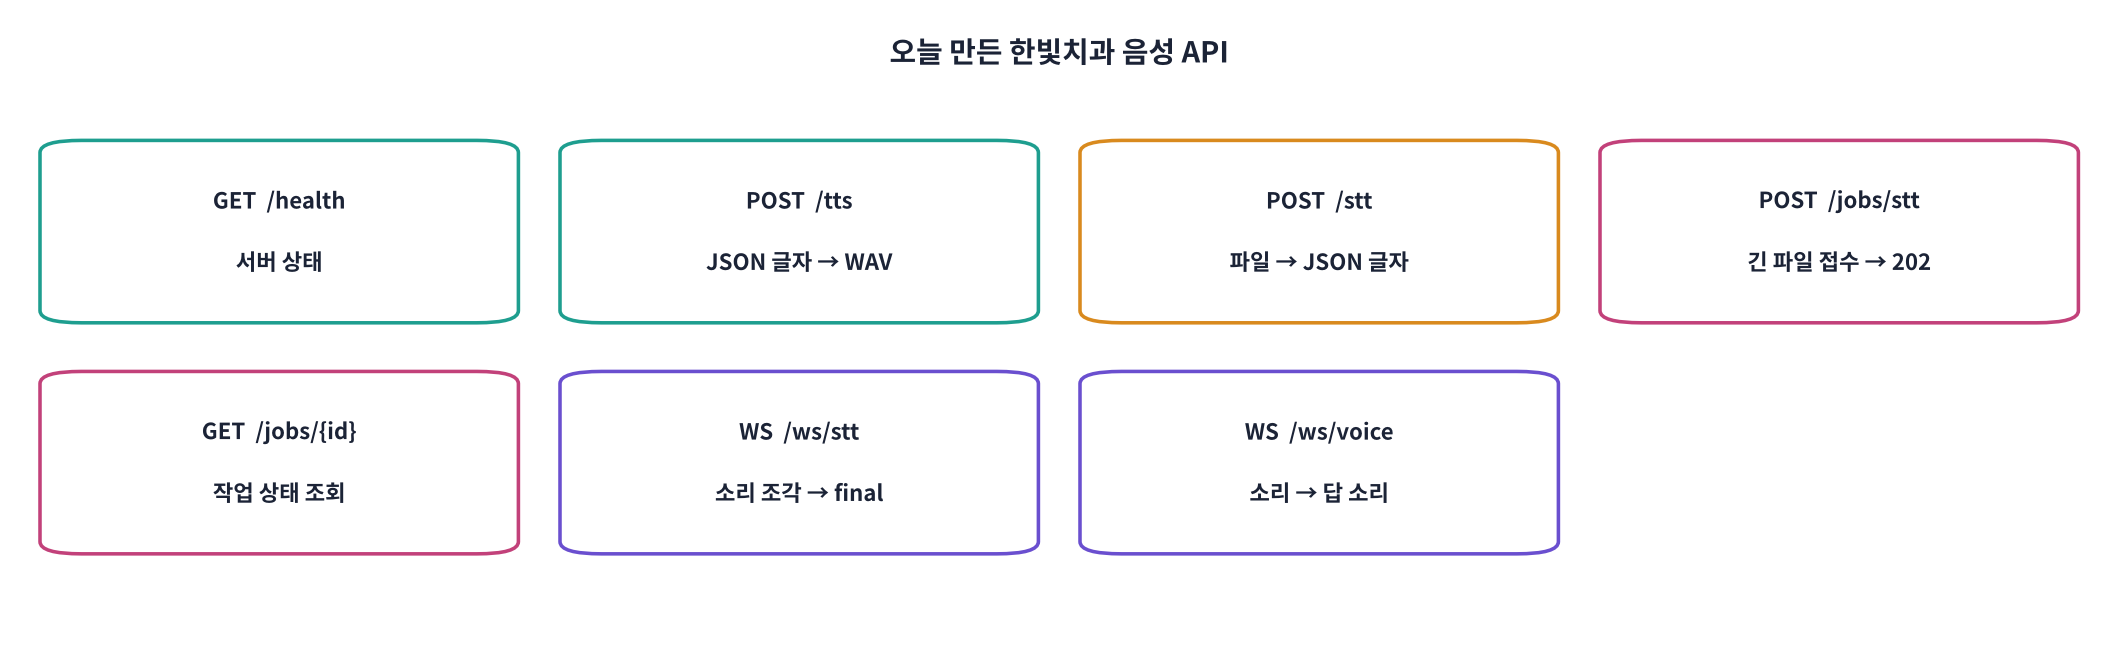

In [ ]:
# 📑 API 명세표 (OpenAPI에서 자동으로) + WebSocket 엔드포인트
spec = (await client.get("/openapi.json")).json()
rows = []
for path, ops in spec["paths"].items():
    for method, op in ops.items():
        body = op.get("requestBody", {}).get("content", {})
        rows.append({"메서드": method.upper(), "경로": path, "설명": op.get("summary", ""),
                     "요청 본문": ", ".join(body) or "-", "성공 코드": ", ".join(k for k in op.get("responses", {}) if k.startswith("2"))})
rows += [{"메서드": "WS", "경로": "/ws/stt", "설명": "실시간 받아쓰기", "요청 본문": "binary PCM16 20 ms · text END", "성공 코드": "101"},
         {"메서드": "WS", "경로": "/ws/voice", "설명": "음성 안내 왕복", "요청 본문": "binary PCM16 20 ms · text END", "성공 코드": "101"}]
display(pd.DataFrame(rows))

server.should_exit = True                                # 🧹 서버 끄기 (다시 쓰려면 start_server())
await client.aclose()
server_thread.join(timeout=5)
print("서버 종료:", not server_thread.is_alive())

| 오늘 만든 것 | FastAPI · 파이썬 이름 | 한 줄 요약 |
|---|---|---|
| 엔드포인트 | `@app.get` · `@app.post` · `@app.websocket` | 주소 + 처리 함수 |
| 요청 검사 | `BaseModel` · `Field` | 틀리면 함수 전에 422 |
| 소리 응답 | `Response(media_type="audio/wav")` | 바이트 + content-type |
| 파일 업로드 | `UploadFile = File(...)` | multipart, `await file.read()` |
| 오류 응답 | `HTTPException(415 · 413 · 400 · 404)` | 4xx = 보낸 쪽 잘못 |
| 막히지 않게 | `asyncio.to_thread` · `asyncio.Semaphore(1)` | 무거운 일은 스레드, GPU는 줄 세우기 |
| 긴 작업 | `BackgroundTasks` · 202 · `GET /jobs/{id}` | 접수증 + 나중에 조회 |
| 실시간 | `ws.accept()` · `receive()` · `send_json` · `send_bytes` | 연결 유지, 소리 조각 ↔ 사건 · 답 소리 |

### ✅ 오늘의 확인
- [ ] `/health` · `/tts` · `/stt`를 `httpx`와 Swagger에서 호출하고, 응답의 상태 코드 · content-type을 읽었다.
- [ ] 형식별 업로드(WAV · FLAC · MP3 · WebM)와 오류(415 · 413 · 400 · 422)를 확인했다.
- [ ] 막힌 이벤트 루프의 `/health` 지연을 재고, `to_thread` · `Semaphore`로 고쳤다.
- [ ] WebSocket으로 실시간 받아쓰기와 음성 안내 왕복을 했다.

### 🔜 D32 예고: 웹 클라이언트
- 브라우저 **마이크 캡처(Web Audio API · MediaRecorder)** → 오늘의 `/stt` · `/ws/stt`로 보내기
- **WebRTC 연결**(D29 LiveKit 웹 클라이언트 복습)과 비교
- 녹음 버튼 · 받아쓰기 표시 · 답 소리 재생이 있는 **간단한 UI**

> 🎬 **애니메이션 D31-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day31/animation.html#recap) — 상황별로 상태 코드 · 비동기 · REST/WS 중 무엇을 고를지